#### Environment and directory setup

In [1]:
import os
import sys
from pathlib import Path
import sys
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().resolve()
print("python:", sys.executable)
# if run from the tools directory, move up one level to the project root
if not (PROJECT_ROOT / "tools").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "tools").is_dir(), (
    f"Cannot locate project root from {Path.cwd()}"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("project root:", PROJECT_ROOT)
load_dotenv(PROJECT_ROOT / ".env")

python: c:\Users\25145857r\.conda\envs\oasis-agent\python.exe
project root: D:\Research\ACM SIGSPATIAL\oasis-agent


True

In [2]:
# Here we test hard-coded values for Los Angeles County, California, USA
state_fips = "06"
county_fips = "037"
place_name = "Los Angeles County, California, USA"

#### Catch and chech tract

In [3]:
# Request ACS data for the specified place using the Census API
import importlib
import tools.data_acquisition.census as census

importlib.reload(census)

demographics = census.fetch_acs(
    state_fips,
    county_fips,
    ["total_population", "elderly_population", "poverty"],
    year=2022,
)

demographics = census.derive_indicators(demographics)
print("Demographics for", place_name, "shape:", demographics.shape)
print(demographics)

Demographics for Los Angeles County, California, USA shape: (2498, 22)
                                                   NAME  total_population  \
0     Census Tract 1011.10; Los Angeles County; Cali...              4014   
1     Census Tract 1011.22; Los Angeles County; Cali...              4164   
2     Census Tract 1012.20; Los Angeles County; Cali...              3481   
3     Census Tract 1012.21; Los Angeles County; Cali...              3756   
4     Census Tract 1012.22; Los Angeles County; Cali...              2808   
...                                                 ...               ...   
2493  Census Tract 9800.38; Los Angeles County; Cali...                 0   
2494  Census Tract 9800.39; Los Angeles County; Cali...                 0   
2495  Census Tract 9901; Los Angeles County; California                 0   
2496  Census Tract 9902; Los Angeles County; California                 0   
2497  Census Tract 9903; Los Angeles County; California                 0   

    

In [4]:
import geopandas as gpd

tracts = census.fetch_tract_geometry(
    state_fips="06",
    county_fips="037",
    year=2022,
)

tracts.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,06,037,137504,06037137504,1375.04,Census Tract 1375.04,G5020,S,3837562,0,+34.1480383,-118.5720594,"MULTIPOLYGON (((-118.58119 34.14318, -118.5809..."
1,06,037,138000,06037138000,1380,Census Tract 1380,G5020,S,4472196,0,+34.1488008,-118.5910495,"MULTIPOLYGON (((-118.60573 34.14585, -118.6056..."
2,06,037,139200,06037139200,1392,Census Tract 1392,G5020,S,1152028,0,+34.1756961,-118.5246446,"MULTIPOLYGON (((-118.53082 34.18024, -118.5295..."
3,06,037,143200,06037143200,1432,Census Tract 1432,G5020,S,957092,0,+34.1494399,-118.3720618,"MULTIPOLYGON (((-118.37899 34.15409, -118.3788..."
4,06,037,201301,06037201301,2013.01,Census Tract 2013.01,G5020,S,866189,0,+34.0882421,-118.1878388,"MULTIPOLYGON (((-118.19304 34.0859, -118.19294..."


In [5]:
print("rows:", len(tracts))
print("CRS:", tracts.crs)
print("geometry types:")
print(tracts.geometry.geom_type.value_counts())
print(tracts[["GEOID", "NAME"]].head())
assert len(tracts) > 2000
assert str(tracts.crs) == "EPSG:4326"
assert tracts["GEOID"].str.len().eq(11).all()
assert tracts["GEOID"].str.startswith("06037").all()
assert tracts["GEOID"].is_unique
assert tracts.geometry.notna().all()
assert not tracts.geometry.is_empty.any()
assert tracts.geometry.is_valid.all()

rows: 2498
CRS: EPSG:4326
geometry types:
MultiPolygon    2498
Name: count, dtype: int64
         GEOID     NAME
0  06037137504  1375.04
1  06037138000     1380
2  06037139200     1392
3  06037143200     1432
4  06037201301  2013.01


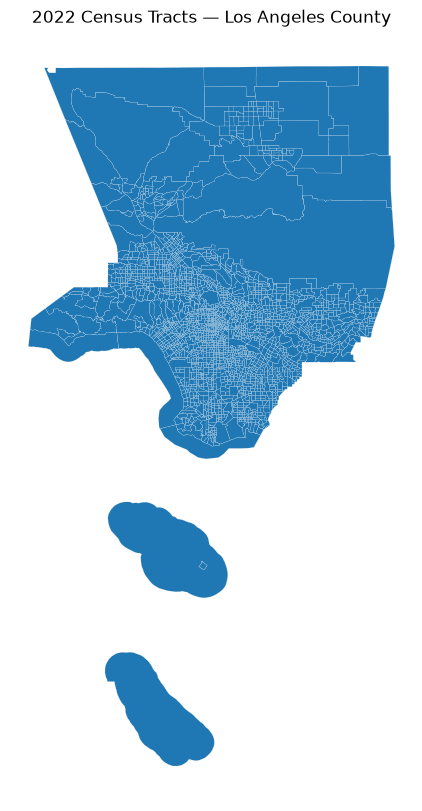

In [6]:
ax = tracts.plot(
    figsize=(10, 10),
    edgecolor="white",
    linewidth=0.1,
)

ax.set_title("2022 Census Tracts — Los Angeles County")
ax.set_axis_off()

#### Merge, classify and visaulized demographics

In [7]:
merged = tracts.merge(
    demographics,
    on="GEOID",
    how="inner",
    validate="one_to_one",
)
join_rate = len(merged) / len(demographics)

print(f"geometry rows: {len(tracts)}")
print(f"demographic rows: {len(demographics)}")
print(f"merged rows: {len(merged)}")
print(f"join rate: {join_rate:.1%}")
print(merged["elderly_ratio"].dtype)
print(merged["elderly_ratio"].isna().sum())

assert join_rate > 0.95

geometry rows: 2498
demographic rows: 2498
merged rows: 2498
join rate: 100.0%
float64
22


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

bins = [
    0.00,
    0.10,
    0.15,
    0.20,
    0.25,
    np.inf,
]

labels = [
    "Below 10%",
    "10% to <15%",
    "15% to <20%",
    "20% to <25%",
    "25% or above",
]

merged["elderly_group"] = pd.cut(
    merged["elderly_ratio"],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True,
)

In [9]:
print(merged["elderly_group"].value_counts(dropna=False).sort_index())

elderly_group
Below 10%       634
10% to <15%     814
15% to <20%     577
20% to <25%     289
25% or above    162
NaN              22
Name: count, dtype: int64


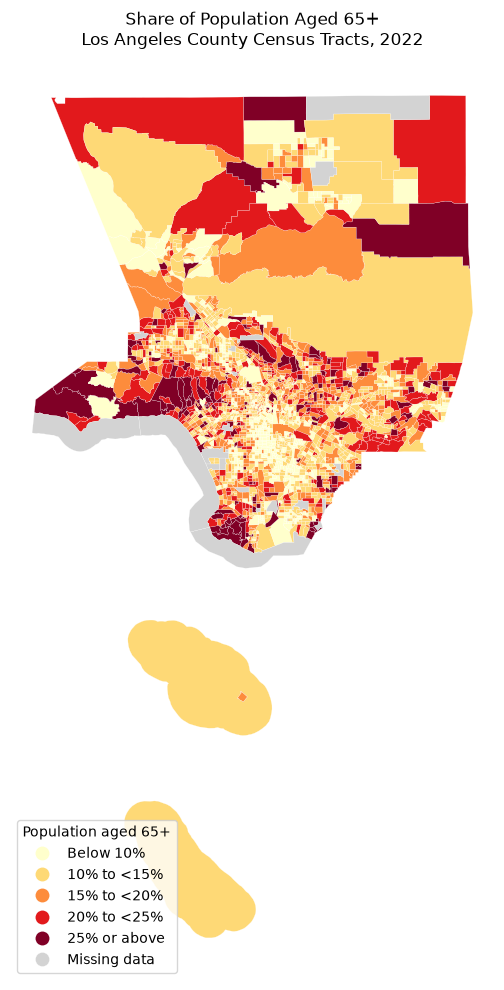

In [10]:
fig, ax = plt.subplots(figsize=(12, 10))

merged.plot(
    column="elderly_group",
    categorical=True,
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.15,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "label": "Missing data",
    },
    legend_kwds={
        "title": "Population aged 65+",
        "loc": "lower left",
        "frameon": True,
    },
    ax=ax,
)

ax.set_title(
    "Share of Population Aged 65+\n"
    "Los Angeles County Census Tracts, 2022"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

#### Landsat LST data, merge and visualize

In [11]:
# Compute summer LST from Landsat 8 imagery using Planetary Computer STAC API
from dotenv import load_dotenv
from tools.data_acquisition.heat import fetch_heat_exposure

load_dotenv()

heat, heat_provenance = fetch_heat_exposure(
    tracts=merged[["GEOID", "geometry"]].copy(),
    start_date="2022-06-01",
    end_date="2022-08-31",
    cloud_cover=20,
    resolution=120,
)

merged = (
    merged.drop(
        columns=["mean_lst", "heat_exposure", "heat_exposure_imputed"],
        errors="ignore",
    )
    .merge(heat, on="GEOID", how="left", validate="one_to_one")
)

lst_median = merged["mean_lst"].median()
merged["heat_exposure"] = merged["mean_lst"].fillna(lst_median)
merged["heat_exposure_imputed"] = merged["mean_lst"].isna()

print(heat_provenance.model_dump())
print("merged rows:", len(merged))
print("observed LST:", merged["mean_lst"].notna().sum())
print("imputed tracts:", merged["heat_exposure_imputed"].sum())

assert len(merged) == len(tracts)
assert merged["heat_exposure"].notna().all()

{'source': 'Landsat 8/9 Collection 2 Level-2 via Microsoft Planetary Computer', 'tier': 'cache', 'record_count': 2498, 'crs': 'EPSG:4326', 'notes': 'tract cache=landsat_lst_61c4bbdb49a14082130b.csv'}
merged rows: 2498
observed LST: 2498
imputed tracts: 0


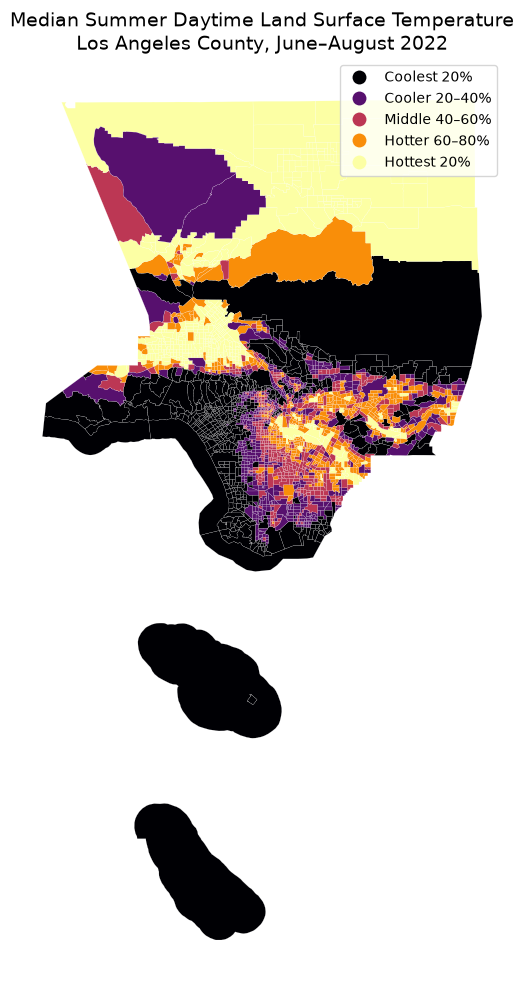

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Coolest 20%",
    "Cooler 20–40%",
    "Middle 40–60%",
    "Hotter 60–80%",
    "Hottest 20%",
]

merged["lst_class"] = pd.qcut(
    merged["mean_lst"],
    q=5,
    labels=labels,
)

ax = merged.plot(
    column="lst_class",
    categorical=True,
    cmap="inferno",
    linewidth=0.1,
    edgecolor="white",
    legend=True,
    missing_kwds={
        "color": "lightgray",
        "label": "No valid Landsat pixels",
    },
    figsize=(10, 12),
)

ax.set_title(
    "Median Summer Daytime Land Surface Temperature\n"
    "Los Angeles County, June–August 2022",
    fontsize=14,
)
ax.set_axis_off()
plt.show()

#### Catch candidate facilities, CRS, visualize

In [13]:
from pathlib import Path
import osmnx as ox

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "tools").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

CACHE_ROOT = PROJECT_ROOT / "data" / "cache"
CACHE_VERSION = "v1"

OSMNX_CACHE = CACHE_ROOT / "osmnx" / CACHE_VERSION
OSMNX_CACHE.mkdir(parents=True, exist_ok=True)

ox.settings.use_cache = True
ox.settings.cache_folder = str(OSMNX_CACHE)

print("OSMnx cache:", ox.settings.cache_folder)

OSMnx cache: D:\Research\ACM SIGSPATIAL\oasis-agent\data\cache\osmnx\v1


In [14]:
# Select candidates for the specified place using OSM data
from tools.data_acquisition.geocoding import resolve_place
from tools.data_acquisition.osm import fetch_candidates

place_name = "Los Angeles County, California, USA"

boundary = resolve_place(place_name)

candidates, candidate_error = fetch_candidates(
    boundary,
    amenities=[
        "library",
        "community_centre",
        "school",
    ],
)

if candidate_error:
    raise RuntimeError(candidate_error.model_dump())

print("candidate count:", len(candidates))
print("CRS:", candidates.crs)

display(candidates.head())

candidate count: 4251
CRS: EPSG:4326


,element,id,geometry,addr:city,addr:housenumber,addr:postcode,addr:state,addr:street,amenity,ele,...,old_wikipedia,check_date:currency:XBT,currency:XBT,payment:lightning,payment:lightning:operator,payment:lightning_contactless,payment:onchain,name:es,lanes,cand_id
0,node,123774379,POINT (-118.21881 34.21201),La Cañada Flintridge,1930,91011,CA,Foothill Boulevard,community_centre,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,node,243805625,POINT (-118.41712 33.95942),Los Angeles,7114,90045,CA,West Manchester Avenue,library,41,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,node,344327189,POINT (-118.30135 34.25825),NaN,NaN,NaN,CA,NaN,library,471,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
3,node,351566474,POINT (-118.09527 34.25472),NaN,NaN,NaN,NaN,NaN,school,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
4,node,352502734,POINT (-118.3991 34.07288),NaN,NaN,NaN,CA,NaN,library,77,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4


In [15]:
print("tract CRS:", tracts.crs)
print("candidate CRS:", candidates.crs)

candidates = candidates.to_crs(tracts.crs)

tract CRS: EPSG:4326
candidate CRS: EPSG:4326


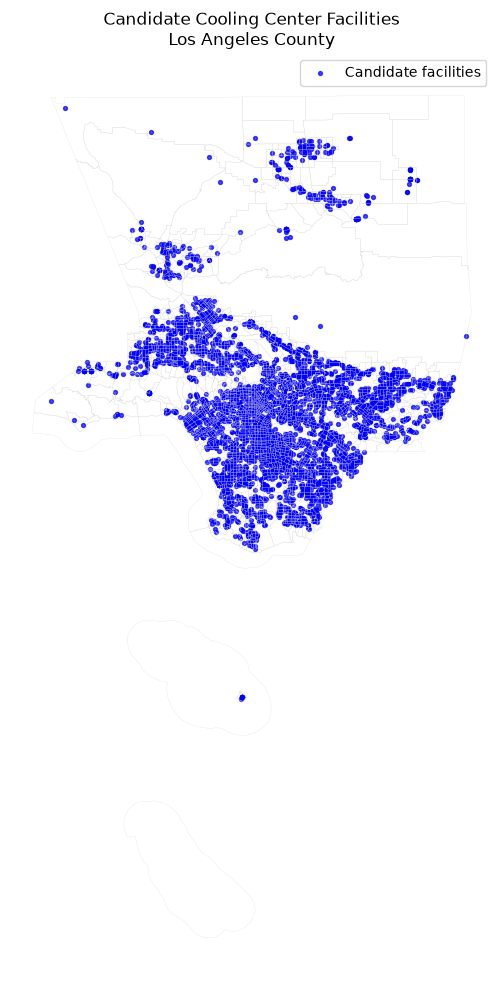

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

merged.boundary.plot(
    ax=ax,
    color="lightgrey",
    linewidth=0.15,
)

candidates.plot(
    ax=ax,
    color="blue",
    markersize=8,
    alpha=0.7,
    label="Candidate facilities",
)

ax.set_title(
    "Candidate Cooling Center Facilities\n"
    "Los Angeles County"
)
ax.legend()
ax.set_axis_off()

plt.tight_layout()
plt.show()

#### Final demand and candidate facilities

In [17]:
from tools.spatial.alignment import centroids, pick_metric_crs

# Population density
metric_crs = pick_metric_crs(merged)
area_km2 = merged.to_crs(metric_crs).geometry.area / 1_000_000

merged["population_density"] = (
    merged["total_population"].astype(float)
    / area_km2.replace(0, np.nan)
)

# Final optimization demand table: define exactly once
demand_areas = merged.loc[
    merged["total_population"].fillna(0).gt(0)
    & merged["elderly_ratio"].notna()
].copy().reset_index(drop=True)

demand_points = centroids(demand_areas).reset_index(drop=True)
population = demand_areas["total_population"].to_numpy(float)

poverty = (
    demand_areas["poverty_rate"]
    .fillna(demand_areas["poverty_rate"].median())
    .to_numpy(float)
)
vulnerable_mask = poverty >= np.quantile(poverty, 0.75)

inside = demand_points.geometry.within(demand_areas.geometry)

print("all tracts:", len(merged))
print("optimization demand:", len(demand_areas))
print("excluded tracts:", len(merged) - len(demand_areas))
print("candidate count:", len(candidates))
print("centroids inside:", inside.sum(), "/", len(demand_points))
print("vulnerable tracts:", vulnerable_mask.sum())

assert len(demand_areas) == len(demand_points) == len(population)
assert demand_areas["GEOID"].tolist() == demand_points["GEOID"].tolist()
assert demand_points.crs == candidates.crs
assert demand_points.geometry.geom_type.eq("Point").all()
assert candidates.geometry.geom_type.eq("Point").all()
assert "heat_exposure" in demand_areas.columns

all tracts: 2498
optimization demand: 2476
excluded tracts: 22
candidate count: 4251
centroids inside: 2459 / 2476
vulnerable tracts: 619


#### Create Haversine matrix

In [18]:
from tools.spatial.accessibility import haversine_matrix, validate_travel_matrix

tm_hav = haversine_matrix(
    demand_points,
    candidates,
    speed_kmh=4.8,
    detour_factor=1.3,
)

matrix_summary = validate_travel_matrix(
    tm_hav,
    len(demand_points),
    len(candidates),
)

print(matrix_summary)
print(f"matrix size: {tm_hav.nbytes / 1024**2:.1f} MB")

for threshold in [10, 15, 20, 30]:
    reachable = (tm_hav <= threshold).any(axis=1)
    covered_population = population[reachable].sum() / population.sum()
    print(f"{threshold:2d} min: {covered_population:.2%}")

assert tm_hav.shape == (len(demand_areas), len(candidates))
assert np.isfinite(tm_hav).all()
assert (tm_hav >= 0).all()

{'shape': (2476, 4251), 'finite_pair_ratio': 1.0, 'unreachable_demand_count': 0, 'min_minutes': 0.030202148229063846, 'max_minutes': 2997.9787688508018, 'nearest_median_minutes': 6.608205059524786, 'nearest_p95_minutes': 22.49044911596625}
matrix size: 80.3 MB
10 min: 76.00%
15 min: 90.35%
20 min: 94.51%
30 min: 97.43%


#### Create ORS test matrix

In [19]:
# Add ORS small block test (here we test 20*20 = 400 demand-supply pairs)
from dotenv import load_dotenv
from tools.spatial.accessibility import network_matrix

load_dotenv()

tm_net_20 = network_matrix(demand_points.head(20), candidates.head(20), source_chunk_size=20, destination_chunk_size=20, max_requests=1,)

tm_hav_20 = haversine_matrix(demand_points.head(20), candidates.head(20),)

valid = np.isfinite(tm_net_20) & (tm_hav_20 > 0)
ratio = tm_net_20[valid] / tm_hav_20[valid]

print("ORS shape:", tm_net_20.shape)
print("ratio mean:", ratio.mean())   # ratio is computed as ORS travel time / haversine travel time
print("ratio std:", ratio.std())

assert tm_net_20.shape == (20, 20)
assert 0.5 < ratio.mean() < 2.0

ORS shape: (20, 20)
ratio mean: 0.9456837890996133
ratio std: 0.0745143937193163


#### Create ORS travel time matrix

In [20]:
MAX_POLICY_THRESHOLD = 20
PRUNING_MARGIN = 1.5
UPPER_WALKING_SPEED_KMH = 6.0

verify_horizon = MAX_POLICY_THRESHOLD * PRUNING_MARGIN

lower_bound_minutes = haversine_matrix(
    demand_points,
    candidates,
    speed_kmh=UPPER_WALKING_SPEED_KMH,
    detour_factor=1.0,
)

ors_eligible = lower_bound_minutes <= verify_horizon

print("eligible pairs:", ors_eligible.sum())
print("demands with no eligible candidate:", (~ors_eligible.any(axis=1)).sum())

eligible pairs: 102045
demands with no eligible candidate: 29


In [21]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()

ORS_BASE_URL = "https://api.heigit.org/openrouteservice/v2/matrix"
url = f"{ORS_BASE_URL}/foot-walking"

response = requests.post(
    url,
    headers={
        "Authorization": os.environ["ORS_API_KEY"],
        "Accept": "application/json",
        "Content-Type": "application/json",
    },
    json={
        "locations": [
            [-118.243683, 34.052235],
            [-118.246800, 34.050700],
        ],
        "sources": ["0"],
        "destinations": ["1"],
        "metrics": ["duration"],
    },
    timeout=30,
)

print("ORS health:", response.status_code)
print(response.text[:300])

ORS health: 200
{"durations":[[308.57]],"destinations":[{"location":[-118.246742,34.050661],"snapped_distance":6.84}],"sources":[{"location":[-118.24368,34.052239],"snapped_distance":0.51}],"metadata":{"attribution":"openrouteservice.org | OpenStreetMap contributors","service":"matrix","timestamp":1785039289063,"qu


In [22]:
import importlib
import tools.spatial.accessibility as accessibility

importlib.invalidate_caches()
accessibility = importlib.reload(accessibility)
sparse_network_matrix = accessibility.sparse_network_matrix

import logging

logging.getLogger("tools.spatial.accessibility").setLevel(logging.INFO)

tm_ors, ors_report = sparse_network_matrix(
    demand_points,
    candidates,
    ors_eligible,
    fallback_matrix=tm_hav,
    mode="walking",
    tile_size_m=3000,
    source_chunk_size=25,
    max_routes_per_request=2500,
    max_requests=500,
    request_interval_s=1.6,
)

print(ors_report)
assert tm_ors.shape == tm_hav.shape

{'router': 'ors_sparse', 'tier': 'cache', 'total_pairs': 10525476, 'eligible_pairs': 102045, 'pruned_pairs': 10423431, 'cache_pairs': 102045, 'live_pairs': 0, 'planned_requests': 0}


In [23]:
print("router:", ors_report["router"])
print("tier:", ors_report["tier"])
print("reason:", ors_report.get("reason"))

router: ors_sparse
tier: cache
reason: None


In [24]:
# Validate the ORS travel time matrix
print(validate_travel_matrix(tm_ors, len(demand_points), len(candidates)))
print("finite eligible pairs:", np.isfinite(tm_ors[ors_eligible]).sum(), "/", ors_eligible.sum())
print("pruned pairs remain inf:", np.isinf(tm_ors[~ors_eligible]).all())

{'shape': (2476, 4251), 'finite_pair_ratio': 0.009695048470967013, 'unreachable_demand_count': 29, 'min_minutes': 0.0, 'max_minutes': 290.70633333333336, 'nearest_median_minutes': 7.338833333333333, 'nearest_p95_minutes': 24.882483333333326}
finite eligible pairs: 102045 / 102045
pruned pairs remain inf: True


#### Set up 4 indicators for optimization

In [25]:
from tools.spatial.alignment import pick_metric_crs

metric_crs = pick_metric_crs(merged)
area_km2 = merged.to_crs(metric_crs).geometry.area / 1_000_000

merged["population_density"] = (
    merged["total_population"].astype(float) / area_km2
)
demand_areas = merged.loc[
    merged["total_population"].fillna(0) > 0
].reset_index(drop=True)

print("demand count:", len(demand_areas))

demand count: 2476


In [26]:
indicator_names = [
    "population_density",
    "elderly_ratio",
    "poverty_rate",
    "heat_exposure",
]

indicators = {
    name: (
        demand_areas[name]
        .fillna(demand_areas[name].median())
        .to_numpy(float)
    )
    for name in indicator_names
}

print("indicator validation:")

for name, values in indicators.items():
    print(
        f"{name:20s}",
        f"min={values.min():.3f}",
        f"max={values.max():.3f}",
        f"std={values.std():.3f}",
    )
    assert values.shape == population.shape
    assert np.isfinite(values).all()
    assert values.std() > 0

assert set(indicators) == {
    "population_density",
    "elderly_ratio",
    "poverty_rate",
    "heat_exposure",
}

indicator validation:
population_density   min=0.235 max=48943.804 std=4453.563
elderly_ratio        min=0.000 max=0.778 std=0.067
poverty_rate         min=0.000 max=1.000 std=0.099
heat_exposure        min=33.779 max=59.135 std=3.398


#### Solve MIP model and visualize results

In [32]:
# Here we use MATRIX_SOURCE = "haversine" for testing
from hitl.knobs import get_weights
from tools.optimization.models import build_demand_weights, solve_mclp

candidate_ids = candidates["cand_id"].astype(str).tolist()
N_FACILITIES = 10
THRESHOLD_MINUTES = 15

def run_weights(profile_name, weights):
    demand_weights = build_demand_weights(
        indicators,
        population,
        weights,
    )

    solution = solve_mclp(
        travel_matrix=tm_ors,  # travel_matrix=tm_ors if using ORS travel times or travel_matrix=tm_hav
        demand_weights=demand_weights,
        population=population,
        vulnerable_mask=vulnerable_mask,
        n_facilities=N_FACILITIES,
        threshold_minutes=THRESHOLD_MINUTES,
        candidate_ids=candidate_ids,
        profile_name=profile_name,
        weights=weights,
        time_limit_s=120,
    )

    return solution, demand_weights

balanced, dw_balanced = run_weights(
    "balanced",
    get_weights("balanced"),
)

cooling, dw_cooling = run_weights(
    "cooling_first",
    get_weights("cooling_first"),
)

print("demand weights identical:", np.allclose(dw_balanced, dw_cooling))
print("weight correlation:", np.corrcoef(dw_balanced, dw_cooling)[0, 1])
print("mean absolute difference:", np.abs(dw_balanced - dw_cooling).mean())

changed = set(balanced.selected_ids) ^ set(cooling.selected_ids)

print("balanced selected:", len(balanced.selected_ids))
print("cooling selected:", len(cooling.selected_ids))
print("changed sites:", changed)

assert balanced.solver_status == "Optimal"
assert cooling.solver_status == "Optimal"
assert not np.allclose(dw_balanced, dw_cooling)
assert len(balanced.selected_ids) <= N_FACILITIES
assert len(cooling.selected_ids) <= N_FACILITIES

demand weights identical: False
weight correlation: 0.9189120409711421
mean absolute difference: 494.4973169318229
balanced selected: 10
cooling selected: 10
changed sites: {'1731', '1101'}


#### Haversine/ORS 11-point sweep and do Pareto analysis

In [33]:
import importlib
import tools.optimization.pareto as pareto

pareto = importlib.reload(pareto)

points = pareto.coverage_pareto_sweep(
    travel_matrix=tm_ors,
    population=population,
    vulnerable_mask=vulnerable_mask,
    candidate_ids=candidate_ids,
    n_facilities=N_FACILITIES,
    threshold_minutes=THRESHOLD_MINUTES,
    steps=11,
)

frontier = pareto.non_dominated(points)

print("swept solutions:", len(points))
print("unique non-dominated outcomes:", len(frontier))

for point in frontier:
    print(
        f"alpha={point.alpha:.1f}",
        f"population={point.efficiency_metric:.6f}",
        f"vulnerable={point.equity_metric:.6f}",
        point.solution.selected_ids,
    )

assert all(p.solution.solver_status == "Optimal" for p in points)
assert points[0].efficiency_metric >= max(p.efficiency_metric for p in points) - 1e-9
assert points[-1].equity_metric >= max(p.equity_metric for p in points) - 1e-9

swept solutions: 11
unique non-dominated outcomes: 4
alpha=0.6 population=0.038405 vulnerable=0.147026 ['180', '298', '752', '1347', '1378', '1817', '1886', '2021', '2627', '4057']
alpha=0.5 population=0.038565 vulnerable=0.146857 ['180', '298', '1347', '1378', '1874', '1886', '2021', '2627', '2729', '4057']
alpha=0.1 population=0.041209 vulnerable=0.143223 ['180', '1378', '1874', '1886', '2073', '2578', '2627', '2729', '4057', '4241']
alpha=0.0 population=0.041602 vulnerable=0.135764 ['180', '222', '1378', '1731', '1817', '1886', '2073', '2578', '4057', '4241']


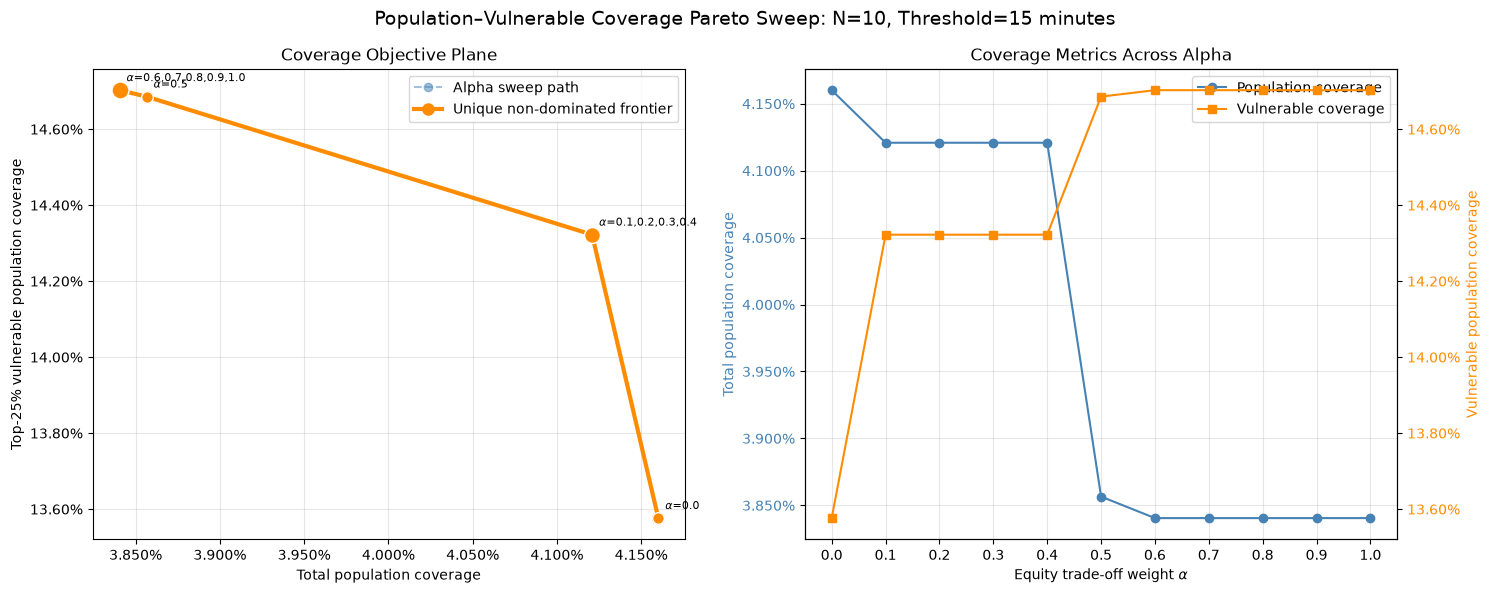

In [29]:
from matplotlib.ticker import PercentFormatter

# Group alphas that produced the same coverage outcome
metric_groups = {}

for point in points:
    key = (
        round(point.efficiency_metric, 10),
        round(point.equity_metric, 10),
    )
    metric_groups.setdefault(key, []).append(point.alpha)

frontier_keys = {
    (
        round(point.efficiency_metric, 10),
        round(point.equity_metric, 10),
    )
    for point in frontier
}

alphas = [point.alpha for point in points]
population_coverage = [point.efficiency_metric for point in points]
vulnerable_coverage = [point.equity_metric for point in points]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# ---------- Left: coverage objective plane ----------

# Dashed line follows alpha order; it is not necessarily the frontier
ax1.plot(
    population_coverage,
    vulnerable_coverage,
    "o--",
    color="steelblue",
    alpha=0.5,
    label="Alpha sweep path",
)

for (x, y), group_alphas in metric_groups.items():
    is_frontier = (x, y) in frontier_keys
    color = "darkorange" if is_frontier else "steelblue"

    ax1.scatter(
        x,
        y,
        s=70 + 20 * (len(group_alphas) - 1),
        color=color,
        edgecolor="white",
        zorder=3,
    )

    alpha_label = ",".join(f"{alpha:.1f}" for alpha in group_alphas)

    ax1.annotate(
        rf"$\alpha$={alpha_label}",
        (x, y),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=8,
    )

ax1.plot(
    [point.efficiency_metric for point in frontier],
    [point.equity_metric for point in frontier],
    "o-",
    color="darkorange",
    linewidth=3,
    markersize=8,
    label="Unique non-dominated frontier",
)

ax1.set_xlabel("Total population coverage")
ax1.set_ylabel("Top-25% vulnerable population coverage")
ax1.set_title("Coverage Objective Plane")
ax1.xaxis.set_major_formatter(PercentFormatter(1))
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax1.grid(alpha=0.3)
ax1.legend()

# ---------- Right: coverage metrics by alpha ----------

ax2.plot(
    alphas,
    population_coverage,
    "o-",
    color="steelblue",
    label="Population coverage",
)

ax2.set_xlabel(r"Equity trade-off weight $\alpha$")
ax2.set_ylabel("Total population coverage", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_xticks(alphas)
ax2.grid(alpha=0.3)

ax2_equity = ax2.twinx()

ax2_equity.plot(
    alphas,
    vulnerable_coverage,
    "s-",
    color="darkorange",
    label="Vulnerable coverage",
)

ax2_equity.set_ylabel(
    "Vulnerable population coverage",
    color="darkorange",
)
ax2_equity.tick_params(axis="y", labelcolor="darkorange")
ax2_equity.yaxis.set_major_formatter(PercentFormatter(1))

ax2.set_title("Coverage Metrics Across Alpha")

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_equity.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="best")

fig.suptitle(
    f"Population–Vulnerable Coverage Pareto Sweep: "
    f"N={N_FACILITIES}, Threshold={THRESHOLD_MINUTES} minutes",
    fontsize=14,
)

fig.tight_layout()
plt.show()

In [30]:
hav_cover = tm_hav <= THRESHOLD_MINUTES
ors_cover = tm_ors <= THRESHOLD_MINUTES

print("Haversine covered pairs:", hav_cover.sum())
print("ORS covered pairs:", ors_cover.sum())
print("ORS gained pairs:", (~hav_cover & ors_cover).sum())
print("ORS lost pairs:", (hav_cover & ~ors_cover).sum())
print("same coverage classification:", (hav_cover == ors_cover).mean())

Haversine covered pairs: 11236
ORS covered pairs: 10289
ORS gained pairs: 950
ORS lost pairs: 1897
same coverage classification: 0.9997295134205807


#### Domain-weight strategy evaluation

In [31]:
# from hitl.knobs import get_weights
# from tools.optimization.models import build_demand_weights, solve_mclp

strategy_names = [
    "efficiency_first",
    "balanced",
    "equity_first",
    "cooling_first",
]

strategy_solutions = {}

for name in strategy_names:
    weights = get_weights(name)

    demand_weights = build_demand_weights(
        indicators,
        population,
        weights,
    )

    solution = solve_mclp(
        travel_matrix=tm_ors,
        demand_weights=demand_weights,
        population=population,
        vulnerable_mask=vulnerable_mask,
        n_facilities=N_FACILITIES,
        threshold_minutes=THRESHOLD_MINUTES,
        candidate_ids=candidate_ids,
        profile_name=name,
        weights=weights,
        time_limit_s=120,
    )

    strategy_solutions[name] = solution

    print(
        name,
        f"population={solution.covered_ratio:.6f}",
        f"vulnerable={solution.vulnerable_covered_ratio:.6f}",
        solution.selected_ids,
    )

efficiency_first population=0.039651 vulnerable=0.122147 ['222', '1101', '1378', '1874', '2073', '2090', '2169', '2578', '2729', '4241']
balanced population=0.040881 vulnerable=0.142502 ['180', '1101', '1378', '1874', '1886', '2073', '2578', '2729', '4057', '4241']
equity_first population=0.041091 vulnerable=0.137149 ['180', '1101', '1378', '1731', '1817', '1886', '2073', '2578', '4057', '4241']
cooling_first population=0.041376 vulnerable=0.138382 ['180', '1378', '1731', '1874', '1886', '2073', '2578', '2729', '4057', '4241']
